# 07b — How the methods behave

Results are in `07a_results.ipynb`. This notebook explains them:

1. **One example run** (`FOCUS_ORDER`, `FOCUS_SEED` in the setup cell) followed stage by stage.
2. **Replay mechanisms over all cells** — which pairs each method replayed, how concentrated and stable that choice was, whether replayed pairs had actually regressed, and the CPMR and DAPR-Gated diagnostics.

## 1. Setup

`FOCUS_ORDER` and `FOCUS_SEED` control only the early step-by-step example. You do not need to change them to see the complete study: the full-grid dashboard near the end always includes all four orders and both seeds. Run the notebook once from top to bottom. Tables are normal HTML, not the large interactive viewer, so they are easier to select and copy.

Set `SAVE_OUTPUTS = True` only when you want CSV tables and PNG figures saved under the CARC artifact directory.


In [1]:
import json, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display

FOCUS_ORDER = 1 # change to see other results
FOCUS_SEED = 0 # change to see other results

SAVE_OUTPUTS = False
os.environ["MFR_OUTPUT_DIR"] = "/project2/xiangren_1987/grp26-mfr-dpo/artifacts"
REPO = next((p for p in [Path.cwd(), Path.cwd().parent]
             if (p/'configs/experiment_protocol.json').exists()), None)
if REPO is None:
    raise FileNotFoundError('Open this notebook from the mfr-dpo repository')
if 'MFR_OUTPUT_DIR' not in os.environ:
    raise EnvironmentError('Set MFR_OUTPUT_DIR to the absolute CARC artifact directory first')
ARTIFACT_DIR = Path(os.environ['MFR_OUTPUT_DIR']).expanduser().resolve()

protocol = json.loads((REPO/'configs/experiment_protocol.json').read_text())
TOLERANCE = protocol['new_learning_tolerance_points']
OUTPUT_DIR = ARTIFACT_DIR/'analysis/notebook_07'
METHODS = protocol['methods'] + protocol['secondary_methods']
MLABEL = {'none':'No replay','random':'Random 10%','random_high':'Random 14.3%',
          'lowest_margin':'Lowest margin','mfr':'MFR 10%','fmcr':'FMCR 10%',
          'cpmr':'CPMR 10%', 'dapr':'DAPR-Strong 10%',
          'dapr_weak':'DAPR (α=0.01)', 'dapr_gated':'DAPR-Gated (α=0.1)',
          'dapr_c':'DAPR-C 10%', 'mir_dpo':'MIR-DPO 10%',
          'copr_adapted':'COPR-adapted 10%', 'ewc_100':'LoRA-EWC (λ=100)',
          'ewc_1000':'LoRA-EWC (λ=1,000)', 'ewc_10000':'LoRA-EWC (λ=10,000)',
          'mfr_balanced':'Balanced MFR 10%', 'mfr_at_risk':'At-Risk MFR 10%'}
MCOLOR = {'none':'#666666','random':'#377bd1','random_high':'#7557c7',
          'lowest_margin':'#20a878','mfr':'#ef6a32','fmcr':'#b52fb5',
          'cpmr':'#7a3db8', 'dapr':'#d68a00', 'dapr_weak':'#e6ad38',
          'dapr_gated':'#8a5a00', 'dapr_c':'#a45c00',
          'mir_dpo':'#008c95', 'copr_adapted':'#b13c63',
          'ewc_100':'#4c78a8', 'ewc_1000':'#355f8a', 'ewc_10000':'#1f3b57',
         'mfr_balanced':'#c0392b', 'mfr_at_risk':'#7b241c'}
for i,method in enumerate(METHODS):
    MLABEL.setdefault(method, method.replace('_',' ').title())
    MCOLOR.setdefault(method, plt.get_cmap('tab10')(i % 10))
DATASETS = ['helpful','safe','quality']
DLABEL = {'helpful':'Helpful','safe':'Safe','quality':'Quality'}
DCOLOR = {'helpful':'#377bd1','safe':'#d14b61','quality':'#20a878'}

def show_table(df, name):
    out=df.copy()
    out.columns.name=None
    out.index.name=None
    nums=out.select_dtypes(include='number').columns
    out[nums]=out[nums].round(2)
    display(HTML(out.to_html(index=False,border=0,na_rep='—',classes='result-table')))
    if SAVE_OUTPUTS:
        OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
        out.to_csv(OUTPUT_DIR/f'{name}.csv',index=False)

def finish(fig,name):
    # Some multi-panel figures already use constrained_layout. Switching them to
    # tight_layout after adding a colorbar raises an error in newer Matplotlib versions.
    if fig.get_layout_engine() is None:
        fig.tight_layout()
    if SAVE_OUTPUTS:
        OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
        fig.savefig(OUTPUT_DIR/f'{name}.png',dpi=200,bbox_inches='tight')
    plt.show()

plt.rcParams.update({'figure.dpi':105,'font.size':9,'axes.spines.top':False,'axes.spines.right':False})
display(HTML('''<style>
.result-table{border-collapse:collapse;font-size:13px;margin:8px 0 16px}
.result-table th{
    background:#333333;
    color:#ffffff;
    font-weight:600;
}
.result-table th,.result-table td{border:1px solid #bbb;padding:5px 9px;text-align:center}
</style>'''))
print('Reading:', ARTIFACT_DIR/'runs')


Reading: /project2/xiangren_1987/grp26-mfr-dpo/artifacts/runs


## 2. Load the completed runs

Only run folders containing `COMPLETE.json`, `settings.json`, and `results.csv` are used. Pilot runs are ignored. This first small table shows what is available.


In [2]:
frames=[]; records={}
for folder in sorted((ARTIFACT_DIR/'runs').glob('*')):
    needed=[folder/'COMPLETE.json',folder/'settings.json',folder/'results.csv']
    if not all(p.exists() for p in needed): continue
    s=json.loads((folder/'settings.json').read_text())
    if str(s.get('protocol_version'))!=str(protocol['protocol_version']): continue
    if str(s.get('method')) not in METHODS: continue  # ignore superseded diagnostic methods
    r={'run_name':s.get('run_name',folder.name),'order_id':int(s['order_id']),
       'order':list(s['order']),'method':str(s['method']),'seed':int(s['seed']),
       'folder':folder,'stage1_from':s.get('stage1_from')}
    records[r['run_name']]=r
    f=pd.read_csv(folder/'results.csv')
    for key in ['run_name','order_id','method','seed']: f[key]=r[key]
    frames.append(f)
if not frames: raise FileNotFoundError('No completed v2 runs were found')
runs=pd.concat(frames,ignore_index=True)
METHODS=[method for method in METHODS if method in set(runs.method)]

inventory=pd.DataFrame([{'Order':r['order_id'],'Sequence':' → '.join(DLABEL[x] for x in r['order']),
                         'Seed':r['seed'],'Method':MLABEL[r['method']]} for r in records.values()])
show_table(inventory.sort_values(['Order','Seed','Method']),'completed_runs')

focus_records={n:r for n,r in records.items() if r['order_id']==FOCUS_ORDER and r['seed']==FOCUS_SEED}
focus=runs[runs.run_name.isin(focus_records)].copy()
if focus.empty: raise ValueError(f'No completed runs for order {FOCUS_ORDER}, seed {FOCUS_SEED}')
focus_methods=[m for m in METHODS if m in set(focus.method)]
order=protocol['orders'][str(FOCUS_ORDER)]
print('Selected:', ' → '.join(DLABEL[x] for x in order), '| seed',FOCUS_SEED)
print('Methods:', ', '.join(MLABEL[m] for m in focus_methods))


Order,Sequence,Seed,Method
1,Helpful → Safe → Quality,0,At-Risk MFR 10%
1,Helpful → Safe → Quality,0,Balanced MFR 10%
1,Helpful → Safe → Quality,0,COPR-adapted 10%
1,Helpful → Safe → Quality,0,CPMR 10%
1,Helpful → Safe → Quality,0,DAPR (α=0.01)
1,Helpful → Safe → Quality,0,DAPR-C 10%
1,Helpful → Safe → Quality,0,DAPR-Gated (α=0.1)
1,Helpful → Safe → Quality,0,DAPR-Strong 10%
1,Helpful → Safe → Quality,0,FMCR 10%
1,Helpful → Safe → Quality,0,"LoRA-EWC (λ=1,000)"


Selected: Helpful → Safe → Quality | seed 0
Methods: No replay, Random 10%, MFR 10%, Random 14.3%, Lowest margin, FMCR 10%, CPMR 10%, DAPR-Strong 10%, DAPR (α=0.01), DAPR-Gated (α=0.1), DAPR-C 10%, MIR-DPO 10%, COPR-adapted 10%, LoRA-EWC (λ=100), LoRA-EWC (λ=1,000), LoRA-EWC (λ=10,000), Balanced MFR 10%, At-Risk MFR 10%


In [3]:
def stage_folder(r,stage):
    d=r['order'][stage-1]; direct=r['folder']/f'stage{stage}_{d}'
    if direct.exists(): return direct
    if stage==1 and r['stage1_from']:
        source=Path(r['stage1_from'])
        if not source.exists(): source=r['folder'].parent/source.name
        return source/f'stage1_{d}'
    return direct


# Part A — One example run

Everything in Part A uses only the order–seed cell chosen in the setup cell.

## 3. Did each stage learn its behavior?

The gain is `score after the stage − score before the stage`. All three datasets are included because every dataset is trained once. Larger positive gain means stronger learning during that stage.


Method,Helpful gain,Safe gain,Quality gain
No replay,27.0,38.5,7.5
Random 10%,27.0,38.0,8.5
MFR 10%,27.0,36.5,13.0
Random 14.3%,27.0,36.5,9.0
Lowest margin,27.0,36.5,10.5
FMCR 10%,27.0,38.0,7.0
CPMR 10%,27.0,37.5,6.0
DAPR-Strong 10%,27.0,32.5,6.5
DAPR (α=0.01),27.0,36.5,5.5
DAPR-Gated (α=0.1),27.0,32.5,8.0


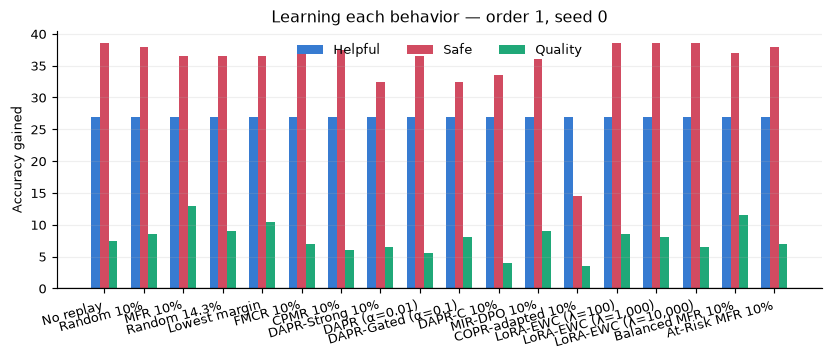

In [4]:
learn=[]
for name,r in focus_records.items():
    part=focus[focus.run_name==name]
    for stage,d in enumerate(r['order'],1):
        before=part[(part.stage==stage-1)&(part.eval_set==d)]
        after=part[(part.stage==stage)&(part.eval_set==d)]
        if len(before) and len(after):
            learn.append({'method':r['method'],'dataset':d,
                          'gain':float(after.iloc[0].accuracy-before.iloc[0].accuracy)})
learning=pd.DataFrame(learn)
wide=learning.pivot(index='method',columns='dataset',values='gain').reindex(focus_methods).reindex(columns=DATASETS)
t=wide.reset_index().rename(columns={'method':'Method',**{d:f'{DLABEL[d]} gain' for d in DATASETS}})
t.Method=t.Method.map(MLABEL); show_table(t,'learning_gain')

x=np.arange(len(focus_methods)); w=.22
fig,ax=plt.subplots(figsize=(8,3.5))
for i,d in enumerate(DATASETS): ax.bar(x+(i-1)*w,wide[d],w,label=DLABEL[d],color=DCOLOR[d])
ax.axhline(0,color='black',lw=.8); ax.grid(axis='y',alpha=.2)
ax.set_xticks(x,[MLABEL[m] for m in focus_methods],rotation=15,ha='right')
ax.set_ylabel('Accuracy gained'); ax.set_title(f'Learning each behavior — order {FOCUS_ORDER}, seed {FOCUS_SEED}')
ax.legend(ncol=3,frameon=False); finish(fig,'01_learning_gain')


## 4. All three behaviors through training

Each small chart includes all three datasets. To keep the figure readable, it shows only the three main methods: No replay, equal-budget Random 10%, and MFR 10%. The secondary methods remain in all result tables and the next chart.

A line should rise when its behavior is trained. A later fall is forgetting.


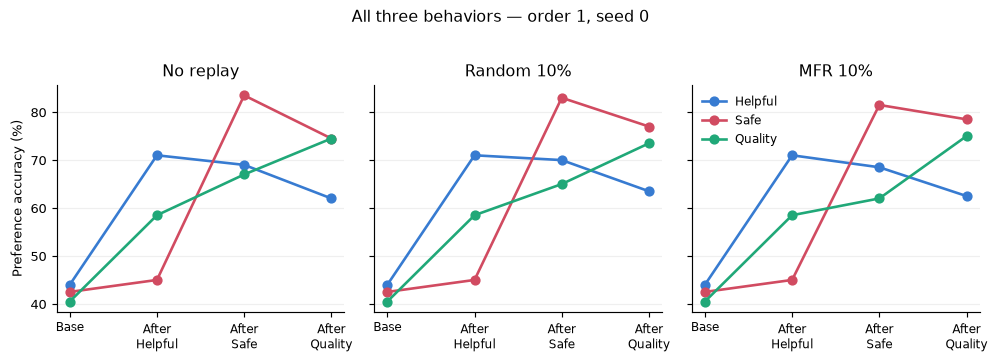

In [5]:
core=[m for m in ['none','random','mfr'] if m in focus_methods]
fig,axes=plt.subplots(1,len(core),figsize=(3.2*len(core),3.3),sharey=True)
axes=np.atleast_1d(axes)
for ax,m in zip(axes,core):
    for d in DATASETS:
        p=focus[(focus.method==m)&(focus.eval_set==d)].sort_values('stage')
        ax.plot(p.stage,p.accuracy,marker='o',lw=1.8,color=DCOLOR[d],label=DLABEL[d])
    ax.set_xticks([0,1,2,3],['Base']+[f'After\n{DLABEL[d]}' for d in order],fontsize=8)
    ax.set_title(MLABEL[m]); ax.grid(axis='y',alpha=.2)
axes[0].set_ylabel('Preference accuracy (%)'); axes[-1].legend(frameon=False,fontsize=8)
fig.suptitle(f'All three behaviors — order {FOCUS_ORDER}, seed {FOCUS_SEED}',y=1.03)
finish(fig,'02_behavior_journey')


## 5. What the final models know

This is the easiest result to show first. It compares all methods after all three stages. Every graph here includes Helpful, Safe, and Quality. The average is useful as a quick summary, but the three separate scores still matter.


Method,Helpful,Safe,Quality,Average
No replay,62.0,74.5,74.5,70.33
Random 10%,63.5,77.0,73.5,71.33
MFR 10%,62.5,78.5,75.0,72.00
Random 14.3%,63.0,77.5,74.0,71.50
Lowest margin,62.5,79.0,75.0,72.17
FMCR 10%,63.0,79.0,74.5,72.17
CPMR 10%,62.5,77.5,75.5,71.83
DAPR-Strong 10%,68.0,77.5,70.0,71.83
DAPR (α=0.01),65.0,81.0,72.0,72.67
DAPR-Gated (α=0.1),68.0,78.0,71.5,72.50


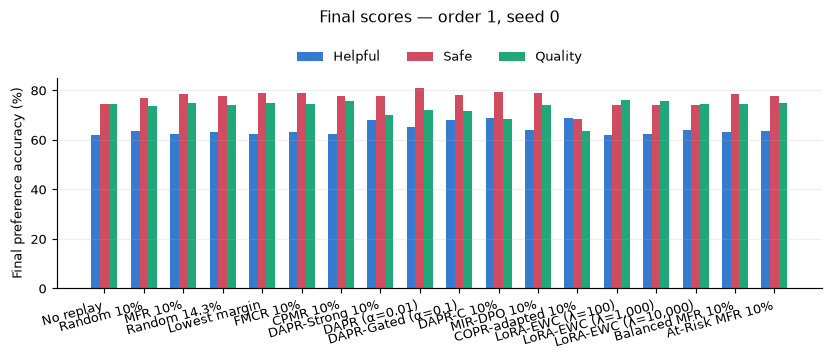

In [6]:
final_stage=len(order)
final=(focus[focus.stage==final_stage].pivot_table(index='method',columns='eval_set',values='accuracy',aggfunc='first')
       .reindex(focus_methods).reindex(columns=DATASETS))
final['average']=final.mean(axis=1)
t=final.reset_index().rename(columns={'method':'Method','helpful':'Helpful','safe':'Safe','quality':'Quality','average':'Average'})
t.Method=t.Method.map(MLABEL); show_table(t,'final_scores')

x=np.arange(len(focus_methods)); w=.22
fig,ax=plt.subplots(figsize=(8,3.5))
for i,d in enumerate(DATASETS): ax.bar(x+(i-1)*w,final[d],w,label=DLABEL[d],color=DCOLOR[d])
ax.set_xticks(x,[MLABEL[m] for m in focus_methods],rotation=15,ha='right')
ax.set_ylabel('Final preference accuracy (%)'); ax.set_title(f'Final scores — order {FOCUS_ORDER}, seed {FOCUS_SEED}',pad=38)
ax.legend(ncol=3,frameon=False,loc='lower center',bbox_to_anchor=(0.5,1.01)); ax.grid(axis='y',alpha=.2); finish(fig,'03_final_scores')


## 6. How much was forgotten

Forgetting is `final score − score immediately after that behavior was learned`. Zero means no forgetting. A negative number means the score fell; closer to zero is better.

**Why one dataset is missing from this graph:** it shows only the first two behaviors in the selected order. The final behavior has no later training after it, so its retention cannot be measured. The table still includes all three columns and marks that final dataset as “Not measurable.”


Method,Helpful,Safe,Quality
No replay,-9.0,-9.0,Not measurable
Random 10%,-7.5,-6.0,Not measurable
MFR 10%,-8.5,-3.0,Not measurable
Random 14.3%,-8.0,-4.0,Not measurable
Lowest margin,-8.5,-2.5,Not measurable
FMCR 10%,-8.0,-4.0,Not measurable
CPMR 10%,-8.5,-5.0,Not measurable
DAPR-Strong 10%,-3.0,0.0,Not measurable
DAPR (α=0.01),-6.0,-0.5,Not measurable
DAPR-Gated (α=0.1),-3.0,0.5,Not measurable


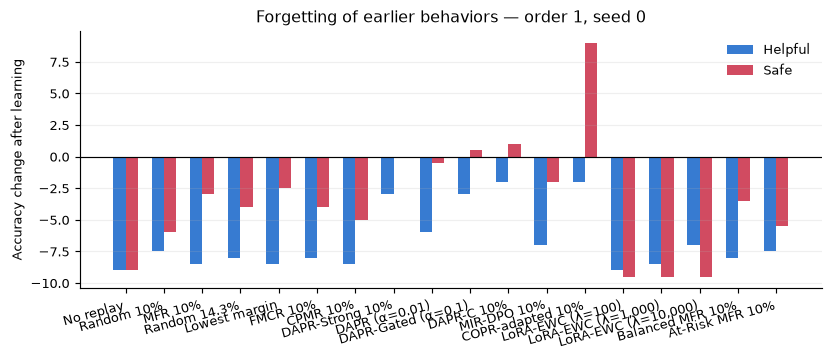

In [7]:
ret=[]
for name,r in focus_records.items():
    p=focus[focus.run_name==name]
    for stage,d in enumerate(r['order'][:-1],1):
        a=p[(p.stage==stage)&(p.eval_set==d)]; z=p[(p.stage==len(r['order']))&(p.eval_set==d)]
        if len(a) and len(z): ret.append({'run_name':name,'method':r['method'],'dataset':d,
                                         'change':float(z.iloc[0].accuracy-a.iloc[0].accuracy)})
retention=pd.DataFrame(ret)
rwide=retention.pivot(index='method',columns='dataset',values='change').reindex(focus_methods)
t=pd.DataFrame({'Method':[MLABEL[m] for m in focus_methods]})
for d in DATASETS: t[DLABEL[d]]=rwide[d].to_numpy() if d in rwide else 'Not measurable'
show_table(t,'forgetting')

old=order[:-1]; x=np.arange(len(focus_methods)); w=.32
fig,ax=plt.subplots(figsize=(8,3.5))
for i,d in enumerate(old): ax.bar(x+(i-.5)*w,rwide[d],w,label=DLABEL[d],color=DCOLOR[d])
ax.axhline(0,color='black',lw=.8); ax.grid(axis='y',alpha=.2)
ax.set_xticks(x,[MLABEL[m] for m in focus_methods],rotation=15,ha='right')
ax.set_ylabel('Accuracy change after learning'); ax.set_title(f'Forgetting of earlier behaviors — order {FOCUS_ORDER}, seed {FOCUS_SEED}')
ax.legend(frameon=False); finish(fig,'04_forgetting')


## 7. Retention versus new-task learning in this cell

In [8]:
summary=[]
for name,r in records.items():
    p=runs[runs.run_name==name]; changes=[]
    for stage,d in enumerate(r['order'][:-1],1):
        a=p[(p.stage==stage)&(p.eval_set==d)]; z=p[(p.stage==len(r['order']))&(p.eval_set==d)]
        if len(a) and len(z): changes.append(float(z.iloc[0].accuracy-a.iloc[0].accuracy))
    z=p[p.stage==len(r['order'])]; task=z[z.eval_set==r['order'][-1]]
    if len(changes)==2 and len(task):
        summary.append({'run_name':name,'order_id':r['order_id'],'seed':r['seed'],'method':r['method'],
                        'old_change':np.mean(changes),'final_task':float(task.iloc[0].accuracy),
                        'final_average':z.accuracy.mean()})
summary=pd.DataFrame(summary)
s=summary[(summary.order_id==FOCUS_ORDER)&(summary.seed==FOCUS_SEED)].set_index('method').reindex(focus_methods)
t=s.reset_index()[['method','old_change','final_task','final_average']].rename(columns={
  'method':'Method','old_change':'Mean old-behavior change','final_task':f'Final {DLABEL[order[-1]]} score','final_average':'Final average of all 3'})
t.Method=t.Method.map(MLABEL); show_table(t,'headline_balance')


Method,Mean old-behavior change,Final Quality score,Final average of all 3
No replay,-9.00,74.5,70.33
Random 10%,-6.75,73.5,71.33
MFR 10%,-5.75,75.0,72.00
Random 14.3%,-6.00,74.0,71.50
Lowest margin,-5.50,75.0,72.17
FMCR 10%,-6.00,74.5,72.17
CPMR 10%,-6.75,75.5,71.83
DAPR-Strong 10%,-1.50,70.0,71.83
DAPR (α=0.01),-3.25,72.0,72.67
DAPR-Gated (α=0.1),-1.25,71.5,72.50


## 8. Pair-level uncertainty in this cell

The bootstrap resamples the same 200 pairs and gives a 95% interval for MFR minus each baseline. Positive favors MFR. If the interval crosses zero, that comparison is not conclusive.

**Why one behavior is absent here:** this bootstrap is only for the selected `FOCUS_ORDER`. The final behavior in that order has no later training, so retention cannot be measured for it inside that cell. With the default Order 1, that behavior is Quality. The full-grid section below uses Orders 3 and 4 to include Quality retention.


Baseline,Behavior,MFR difference,95% low,95% high,Interval excludes zero?
Random 10%,Helpful,-1.0,-3.0,1.0,No
Random 10%,Safe,3.0,0.0,6.0,No
Random 14.3%,Helpful,-0.5,-2.5,1.5,No
Random 14.3%,Safe,1.0,-1.5,3.5,No
Lowest margin,Helpful,0.0,-2.5,2.5,No
Lowest margin,Safe,-0.5,-2.5,1.0,No


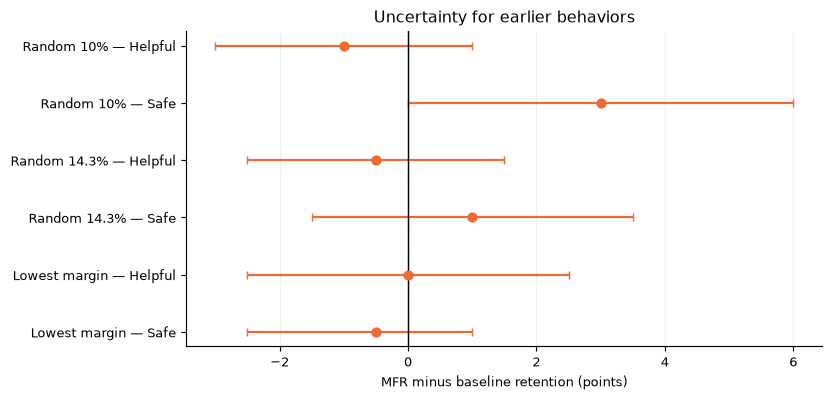

In [9]:
def pair_change(r,stage,d):
    a=pd.read_csv(stage_folder(r,stage)/f'margins_{d}_val.csv')[['id','margin']].rename(columns={'margin':'a'})
    z=pd.read_csv(stage_folder(r,len(r['order']))/f'margins_{d}_val.csv')[['id','margin']].rename(columns={'margin':'z'})
    q=a.merge(z,on='id'); q['change']=(q.z>0).astype(int)-(q.a>0).astype(int)
    return q[['id','change']]

boots=[]
for baseline in ['random','random_high','lowest_margin']:
    by_method={r['method']:r for r in focus_records.values()}
    if not {'mfr',baseline}<=set(by_method): continue
    for stage,d in enumerate(order[:-1],1):
        a=pair_change(by_method['mfr'],stage,d); b=pair_change(by_method[baseline],stage,d)
        q=a.merge(b,on='id',suffixes=('_mfr','_base'))
        diff=100*(q.change_mfr-q.change_base).to_numpy()
        rng=np.random.default_rng(100+stage+10*METHODS.index(baseline))
        samples=rng.choice(diff,size=(5000,len(diff)),replace=True).mean(axis=1)
        lo,hi=np.quantile(samples,[.025,.975])
        boots.append({'Baseline':MLABEL[baseline],'Behavior':DLABEL[d],'MFR difference':diff.mean(),
                      '95% low':lo,'95% high':hi,'Interval excludes zero?':'Yes' if lo>0 or hi<0 else 'No'})
boot=pd.DataFrame(boots); show_table(boot,'bootstrap_intervals')
if len(boot):
    y=np.arange(len(boot)); center=boot['MFR difference'].to_numpy()
    fig,ax=plt.subplots(figsize=(8,.38*len(boot)+1.6))
    ax.errorbar(center,y,xerr=[center-boot['95% low'],boot['95% high']-center],fmt='o',color=MCOLOR['mfr'],capsize=3)
    ax.axvline(0,color='black',lw=1); ax.set_yticks(y,[f'{r.Baseline} — {r.Behavior}' for _,r in boot.iterrows()]); ax.invert_yaxis()
    ax.set_xlabel('MFR minus baseline retention (points)'); ax.set_title('Uncertainty for earlier behaviors'); ax.grid(axis='x',alpha=.2)
    finish(fig,'05_uncertainty')


## 9. What was replayed in this cell

Replay slots count repeats; unique pairs count different examples. Uses per pair shows how concentrated replay was.

The source table includes all three datasets. The final behavior is zero because there is no later stage where it could become old replay data.


In [10]:
rows=[]
for r in focus_records.values():
    for stage in range(2,len(r['order'])+1):
        path=stage_folder(r,stage)/'replay_log.csv'
        if not path.exists(): continue
        log=pd.read_csv(path)
        if log.empty: continue
        n=log.id.nunique(); counts=log.dataset.value_counts()
        rows.append({'Method':MLABEL[r['method']],'Stage':stage,'Learning now':DLABEL[r['order'][stage-1]],
                     'Replay slots':len(log),'Unique pairs':n,'Uses per pair':len(log)/n,
                     'From Helpful':int(counts.get('helpful',0)),'From Safe':int(counts.get('safe',0)),'From Quality':int(counts.get('quality',0))})
replay=pd.DataFrame(rows)
show_table(replay[['Method','Stage','Learning now','Replay slots','Unique pairs','Uses per pair']],'replay_amount')
show_table(replay[['Method','Stage','From Helpful','From Safe','From Quality']],'replay_sources')


Method,Stage,Learning now,Replay slots,Unique pairs,Uses per pair
COPR-adapted 10%,2,Safe,222,133,1.67
COPR-adapted 10%,3,Quality,222,140,1.59
CPMR 10%,2,Safe,222,116,1.91
CPMR 10%,3,Quality,222,61,3.64
DAPR-C 10%,2,Safe,222,168,1.32
DAPR-C 10%,3,Quality,222,137,1.62
DAPR-Gated (α=0.1),2,Safe,222,135,1.64
DAPR-Gated (α=0.1),3,Quality,222,102,2.18
DAPR-Strong 10%,2,Safe,222,168,1.32
DAPR-Strong 10%,3,Quality,222,133,1.67


Method,Stage,From Helpful,From Safe,From Quality
COPR-adapted 10%,2,222,0,0
COPR-adapted 10%,3,52,170,0
CPMR 10%,2,222,0,0
CPMR 10%,3,91,131,0
DAPR-C 10%,2,222,0,0
DAPR-C 10%,3,139,83,0
DAPR-Gated (α=0.1),2,222,0,0
DAPR-Gated (α=0.1),3,146,76,0
DAPR-Strong 10%,2,222,0,0
DAPR-Strong 10%,3,134,88,0


## 10. What it cost in this cell

The first table and chart include time from all three training datasets. The second table shows total examples, replay examples, and extra candidate-scoring time.


Method,Helpful minutes,Safe minutes,Quality minutes,Total minutes
No replay,8.75,4.46,8.77,21.97
Random 10%,8.75,5.45,9.48,23.67
MFR 10%,8.75,7.96,11.07,27.78
Random 14.3%,8.75,5.80,9.75,24.30
Lowest margin,8.75,8.15,11.22,28.12
FMCR 10%,8.75,8.82,11.58,29.15
CPMR 10%,8.75,16.51,22.57,47.83
DAPR-Strong 10%,8.75,9.60,12.04,30.39
DAPR (α=0.01),8.75,9.66,12.17,30.58
DAPR-Gated (α=0.1),8.75,10.02,12.50,31.26


Method,Scoring minutes,Steps,Examples,Replay examples
No replay,0.00,336,6000,0
Random 10%,0.00,336,6444,444
MFR 10%,4.34,336,6444,444
Random 14.3%,0.00,336,6666,666
Lowest margin,4.34,336,6444,444
FMCR 10%,5.40,336,6444,444
CPMR 10%,24.07,336,6444,444
DAPR-Strong 10%,4.41,336,6444,444
DAPR (α=0.01),4.44,336,6444,444
DAPR-Gated (α=0.1),5.25,336,6444,444


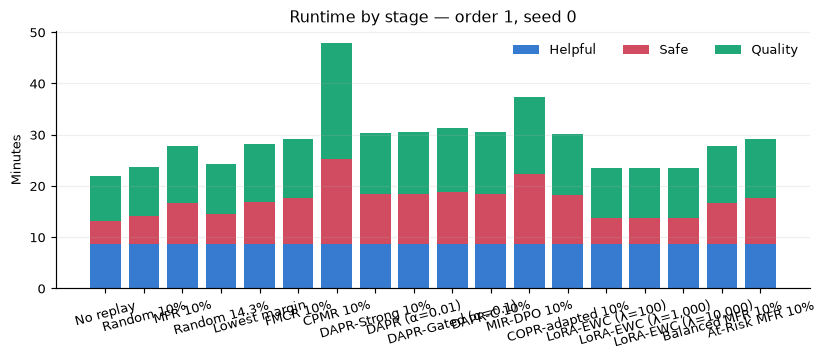

In [11]:
rows=[]
for r in focus_records.values():
    mins={d:0. for d in DATASETS}; total=scoring=0.; steps=examples=replayed=0
    for stage,d in enumerate(r['order'],1):
        path=stage_folder(r,stage)/'history.csv'
        if not path.exists(): continue
        h=pd.read_csv(path); mins[d]=float(h.minutes.max()); total+=mins[d]; steps+=len(h)
        if 'scoring_minutes' in h: scoring+=float(h.scoring_minutes.max())
        if 'n_new' in h:
            nr=int(h.n_replay.sum()) if 'n_replay' in h else 0
            examples+=int(h.n_new.sum())+nr; replayed+=nr
    rows.append({'key':r['method'],'Method':MLABEL[r['method']],**{f'{DLABEL[d]} minutes':mins[d] for d in DATASETS},
                 'Total minutes':total,'Scoring minutes':scoring,'Steps':steps,'Examples':examples,'Replay examples':replayed})
cost=pd.DataFrame(rows); cost['key']=pd.Categorical(cost.key,METHODS,ordered=True); cost=cost.sort_values('key')
show_table(cost[['Method','Helpful minutes','Safe minutes','Quality minutes','Total minutes']],'runtime')
show_table(cost[['Method','Scoring minutes','Steps','Examples','Replay examples']],'cost_budget')
fig,ax=plt.subplots(figsize=(8,3.5)); bottom=np.zeros(len(cost))
for d in DATASETS:
    v=cost[f'{DLABEL[d]} minutes'].to_numpy(); ax.bar(cost.Method,v,bottom=bottom,label=DLABEL[d],color=DCOLOR[d]); bottom+=v
ax.set_ylabel('Minutes'); ax.set_title(f'Runtime by stage — order {FOCUS_ORDER}, seed {FOCUS_SEED}'); ax.tick_params(axis='x',rotation=15)
ax.legend(ncol=3,frameon=False); ax.grid(axis='y',alpha=.2); finish(fig,'06_runtime')


# Part B — Replay mechanisms over all cells

## 11. Which pairs did each method choose?

The accuracy results tell us **which method worked**. This section helps explain **why** by reading the saved `replay_log.csv` files. It uses every completed order, seed, stage, and refresh interval in one run. No model training is repeated.

The main overlap measures are:

- **Unique-pair Jaccard:** the fraction of distinct selected pairs shared by two methods. 0 means no overlap and 1 means identical sets.
- **Weighted Jaccard:** also counts how often each pair was replayed. This becomes smaller when two methods choose the same pairs but repeat them differently.
- **Chance-adjusted overlap:** removes the overlap expected just from selecting pairs from the same 500-pair buffer. 0 means chance-level overlap; positive values mean more agreement than chance.
- **Allocation similarity:** compares how replay slots were divided across Helpful, Safe, and Quality. 1 means the same dataset mixture.

No Replay is not included here because it selects no old examples.


In [12]:
from collections import Counter
from itertools import combinations

replay_parts=[]
for r in records.values():
    if r['method']=='none':
        continue
    for stage in range(2,len(r['order'])+1):
        path=stage_folder(r,stage)/'replay_log.csv'
        if not path.exists():
            continue
        log=pd.read_csv(path)
        if log.empty or not {'id','dataset','interval'}<=set(log.columns):
            continue
        log=log.copy()
        log['run_name']=r['run_name']; log['order_id']=r['order_id']; log['seed']=r['seed']
        log['stage']=stage; log['method']=r['method']; log['trained_on']=r['order'][stage-1]
        replay_parts.append(log)
if not replay_parts:
    raise FileNotFoundError('No replay logs were found in the completed run folders')
replay=pd.concat(replay_parts,ignore_index=True)
replay['interval']=replay['interval'].astype(int)
replay_methods=[m for m in METHODS if m!='none' and m in set(replay.method)]

coverage=(replay.groupby('method').agg(
    Runs=('run_name','nunique'),
    **{'Replay slots':('id','size'),'Unique pairs':('id','nunique')})
    .reindex(replay_methods).reset_index().rename(columns={'method':'Method'}))
stage_counts=(replay[['method','run_name','stage']].drop_duplicates()
              .groupby('method').size().reindex(replay_methods))
coverage.insert(2,'Stages',stage_counts.to_numpy())
coverage.Method=coverage.Method.map(MLABEL)
show_table(coverage,'replay_log_coverage')


Method,Runs,Stages,Replay slots,Unique pairs
Random 10%,8,16,3552,1549
MFR 10%,8,16,3552,1116
Random 14.3%,8,16,5328,1934
Lowest margin,8,16,3552,945
FMCR 10%,8,16,3552,887
CPMR 10%,8,16,3552,890
DAPR-Strong 10%,8,16,3552,1106
DAPR (α=0.01),8,16,3552,995
DAPR-Gated (α=0.1),8,16,3552,981
DAPR-C 10%,8,16,3552,1088


Method A,Method B,Comparisons,Unique Jaccard,Weighted Jaccard,Chance-adjusted,Allocation similarity
MFR 10%,Balanced MFR 10%,80,0.71,0.71,0.80,0.88
FMCR 10%,At-Risk MFR 10%,80,0.70,0.70,0.80,1.00
Random 10%,Random 14.3%,80,0.67,0.67,1.00,0.99
DAPR-Strong 10%,DAPR-C 10%,80,0.58,0.58,0.68,0.98
Lowest margin,CPMR 10%,80,0.55,0.55,0.67,0.96
DAPR (α=0.01),DAPR-Gated (α=0.1),80,0.48,0.48,0.59,0.97
Lowest margin,DAPR (α=0.01),80,0.41,0.41,0.50,0.90
DAPR (α=0.01),DAPR-C 10%,80,0.40,0.40,0.49,0.96
DAPR-Strong 10%,DAPR (α=0.01),80,0.39,0.39,0.48,0.95
DAPR-Gated (α=0.1),DAPR-C 10%,80,0.38,0.38,0.47,0.97


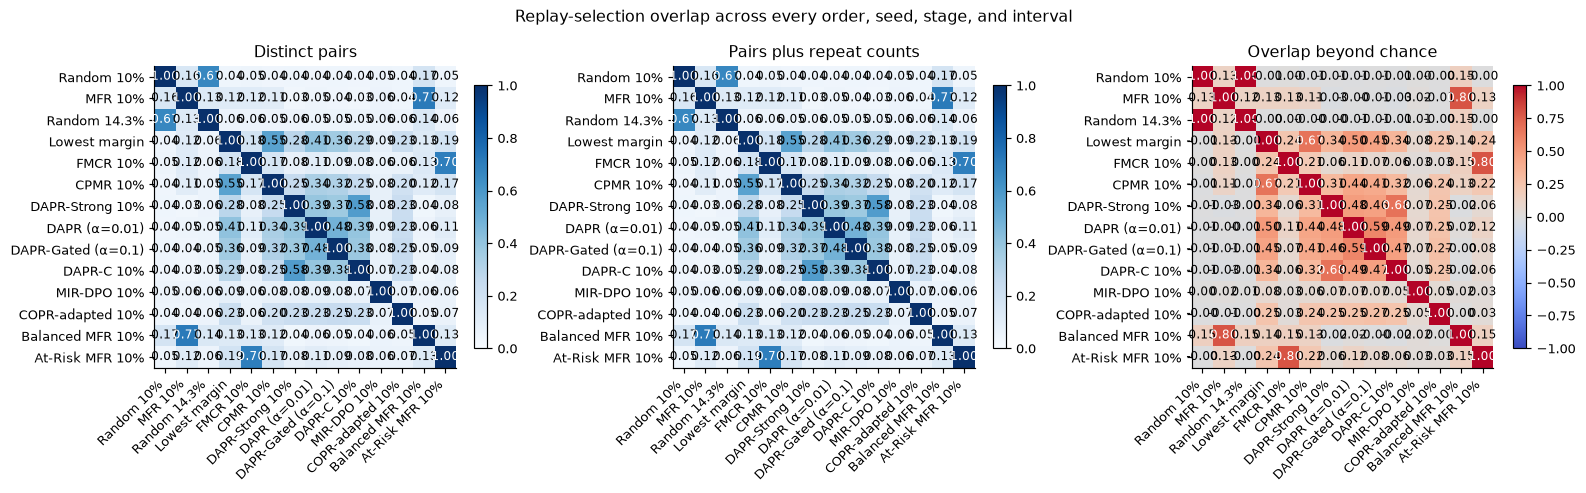

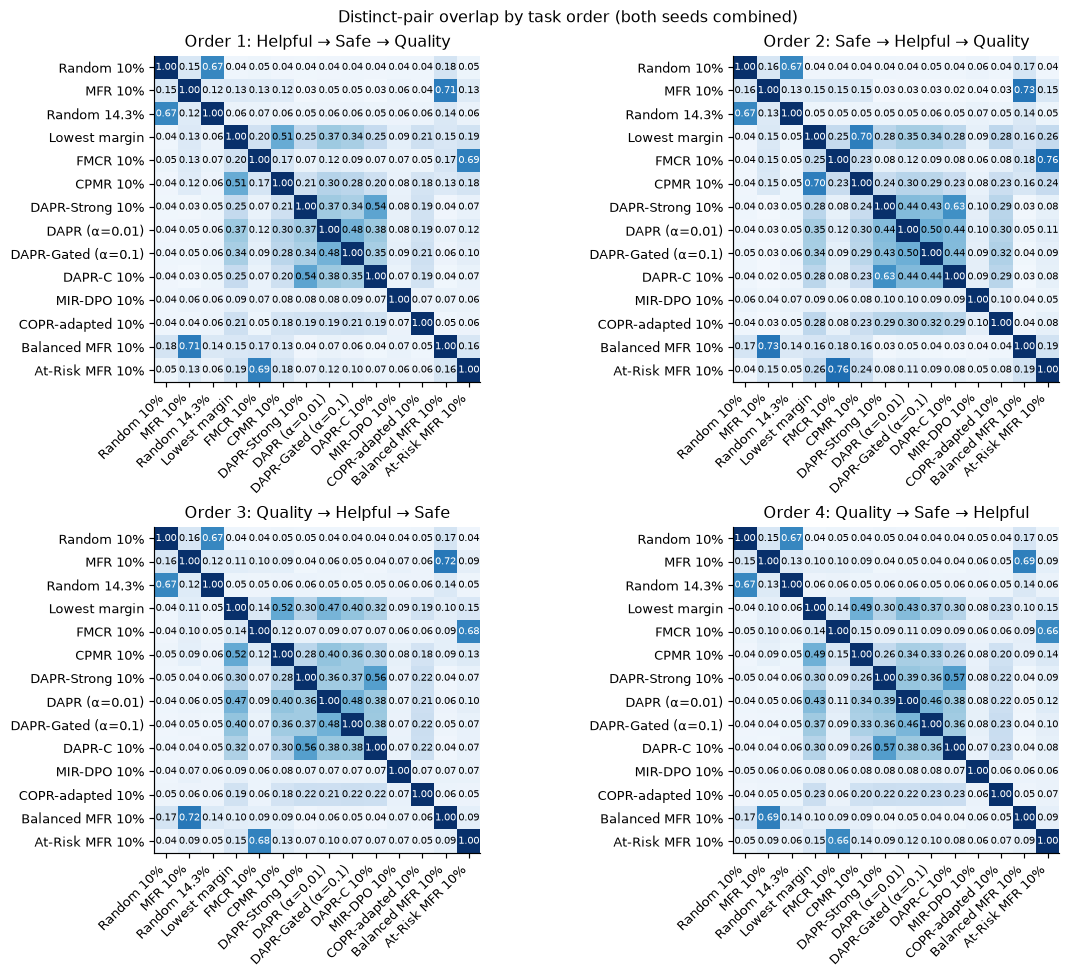

In [13]:
def weighted_jaccard(left,right):
    a,b=Counter(left),Counter(right); keys=set(a)|set(b)
    return sum(min(a[k],b[k]) for k in keys)/sum(max(a[k],b[k]) for k in keys)

def allocation_similarity(left,right):
    a=pd.Series(left).value_counts(normalize=True); b=pd.Series(right).value_counts(normalize=True)
    return 1-.5*sum(abs(a.get(d,0)-b.get(d,0)) for d in DATASETS)

interval_groups={(int(o),int(seed),int(stage),int(interval),method):g for
    (o,seed,stage,interval,method),g in replay.groupby(['order_id','seed','stage','interval','method'])}
contexts=sorted({key[:4] for key in interval_groups})
overlap_rows=[]; buffer_size=int(protocol.get('buffer_size',500))
for context in contexts:
    available=[m for m in replay_methods if (*context,m) in interval_groups]
    for left,right in combinations(available,2):
        a=interval_groups[(*context,left)]; b=interval_groups[(*context,right)]
        aset,bset=set(a.id),set(b.id); intersection=len(aset&bset); union=len(aset|bset)
        expected=len(aset)*len(bset)/buffer_size
        maximum=min(len(aset),len(bset))
        adjusted=(intersection-expected)/(maximum-expected) if maximum>expected else np.nan
        overlap_rows.append({'order_id':context[0],'seed':context[1],'stage':context[2],
            'interval':context[3],'method_a':left,'method_b':right,
            'unique_jaccard':intersection/union if union else np.nan,
            'weighted_jaccard':weighted_jaccard(a.id,b.id),
            'chance_adjusted':adjusted,
            'allocation_similarity':allocation_similarity(a.dataset,b.dataset)})
overlap=pd.DataFrame(overlap_rows)
pairwise=(overlap.groupby(['method_a','method_b']).agg(
    Comparisons=('unique_jaccard','size'),
    **{'Unique Jaccard':('unique_jaccard','mean'),'Weighted Jaccard':('weighted_jaccard','mean'),
       'Chance-adjusted':('chance_adjusted','mean'),'Allocation similarity':('allocation_similarity','mean')})
    .reset_index().sort_values('Unique Jaccard',ascending=False))
pairwise['Method A']=pairwise.method_a.map(MLABEL); pairwise['Method B']=pairwise.method_b.map(MLABEL)
show_table(pairwise[['Method A','Method B','Comparisons','Unique Jaccard','Weighted Jaccard',
                     'Chance-adjusted','Allocation similarity']].round(3),'selection_overlap_all')
if SAVE_OUTPUTS:
    overlap.to_csv(OUTPUT_DIR/'selection_overlap_by_interval.csv',index=False)
    pairwise.to_csv(OUTPUT_DIR/'selection_overlap_summary.csv',index=False)

def overlap_matrix(frame,metric):
    matrix=pd.DataFrame(np.full((len(replay_methods),len(replay_methods)),np.nan),
                        index=replay_methods,columns=replay_methods)
    np.fill_diagonal(matrix.values,1.0)
    for _,row in frame.iterrows():
        matrix.loc[row.method_a,row.method_b]=row[metric]
        matrix.loc[row.method_b,row.method_a]=row[metric]
    return matrix

means=overlap.groupby(['method_a','method_b'],as_index=False).mean(numeric_only=True)
fig,axes=plt.subplots(1,3,figsize=(15,4.6),constrained_layout=True)
for ax,metric,title,cmap,limits in zip(axes,
    ['unique_jaccard','weighted_jaccard','chance_adjusted'],
    ['Distinct pairs','Pairs plus repeat counts','Overlap beyond chance'],
    ['Blues','Blues','coolwarm'],[(0,1),(0,1),(-1,1)]):
    matrix=overlap_matrix(means,metric)
    image=ax.imshow(matrix,vmin=limits[0],vmax=limits[1],cmap=cmap)
    ax.set_xticks(range(len(matrix)),[MLABEL[m] for m in matrix],rotation=45,ha='right')
    ax.set_yticks(range(len(matrix)),[MLABEL[m] for m in matrix]); ax.set_title(title)
    for i in range(len(matrix)):
        for j in range(len(matrix)):
            value=matrix.iloc[i,j]; label='—' if pd.isna(value) else f'{value:.2f}'
            ax.text(j,i,label,ha='center',va='center',fontsize=8,
                    color='white' if pd.notna(value) and abs(value)>.6 else 'black')
    fig.colorbar(image,ax=ax,shrink=.72)
fig.suptitle('Replay-selection overlap across every order, seed, stage, and interval')
finish(fig,'14_selection_overlap_all')

orders=sorted(overlap.order_id.unique()); ncols=2; nrows=int(np.ceil(len(orders)/ncols))
fig,axes=plt.subplots(nrows,ncols,figsize=(11,4.6*nrows),constrained_layout=True,squeeze=False)
for ax,o in zip(axes.flat,orders):
    order_means=overlap[overlap.order_id==o].groupby(['method_a','method_b'],as_index=False).mean(numeric_only=True)
    matrix=overlap_matrix(order_means,'unique_jaccard'); image=ax.imshow(matrix,vmin=0,vmax=1,cmap='Blues')
    ax.set_xticks(range(len(matrix)),[MLABEL[m] for m in matrix],rotation=45,ha='right')
    ax.set_yticks(range(len(matrix)),[MLABEL[m] for m in matrix])
    ax.set_title(f"Order {o}: {' → '.join(DLABEL[d] for d in protocol['orders'][str(o)])}")
    for i in range(len(matrix)):
        for j in range(len(matrix)):
            value=matrix.iloc[i,j]; label='—' if pd.isna(value) else f'{value:.2f}'
            ax.text(j,i,label,ha='center',va='center',fontsize=7,
                    color='white' if pd.notna(value) and value>.6 else 'black')
for ax in axes.flat[len(orders):]: ax.axis('off')
fig.suptitle('Distinct-pair overlap by task order (both seeds combined)')
finish(fig,'15_selection_overlap_by_order')


## 12. Repetition, diversity and behavior allocation

A method can protect an old behavior by replaying many different pairs or by repeatedly rehearsing a small group. The next table and figure measure this difference. **Effective pairs** is a diversity score: it is high when replay is spread evenly and low when a few pairs receive most slots.

The allocation chart intentionally uses **Stage 3 only**. Stage 2 has only one old behavior, so there is no meaningful choice between datasets. At Stage 3 there are two old behaviors. Combining all four orders still places Helpful, Safe, and Quality in the chart.


Method,Run-stages,Mean slots,Mean unique pairs,Repeat rate (%),Top-10 slot share (%),Effective pairs
Random 10%,16,222.0,185.50,16.44,10.92,175.09
MFR 10%,16,222.0,126.94,42.82,18.22,109.18
Random 14.3%,16,333.0,256.25,23.05,8.93,237.46
Lowest margin,16,222.0,117.00,47.30,21.28,98.99
FMCR 10%,16,222.0,117.81,46.93,20.16,99.58
CPMR 10%,16,222.0,107.06,51.77,22.10,88.90
DAPR-Strong 10%,16,222.0,149.44,32.69,18.86,130.12
DAPR (α=0.01),16,222.0,131.00,40.99,20.86,110.58
DAPR-Gated (α=0.1),16,222.0,123.88,44.20,21.40,102.41
DAPR-C 10%,16,222.0,148.00,33.33,18.89,128.59


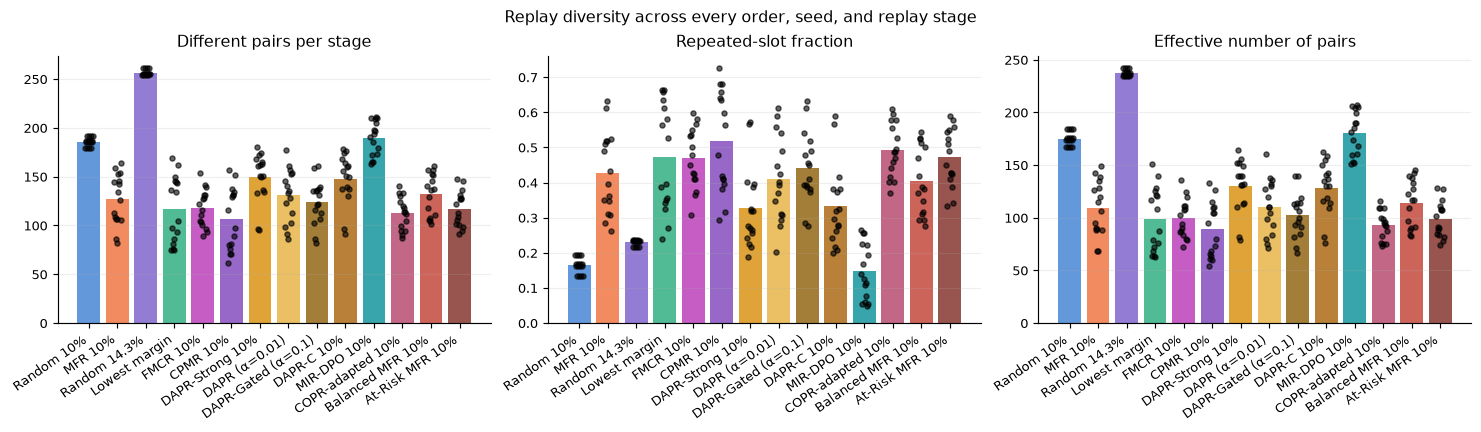

Method,Helpful,Safe,Quality
Random 10%,36.9,36.9,26.1
MFR 10%,23.8,52.4,23.8
Random 14.3%,37.1,37.1,25.8
Lowest margin,37.6,40.3,22.1
FMCR 10%,37.5,37.5,25.0
CPMR 10%,36.7,41.9,21.4
DAPR-Strong 10%,53.0,26.4,20.6
DAPR (α=0.01),52.1,23.8,24.1
DAPR-Gated (α=0.1),50.7,26.4,22.9
DAPR-C 10%,53.5,26.3,20.2


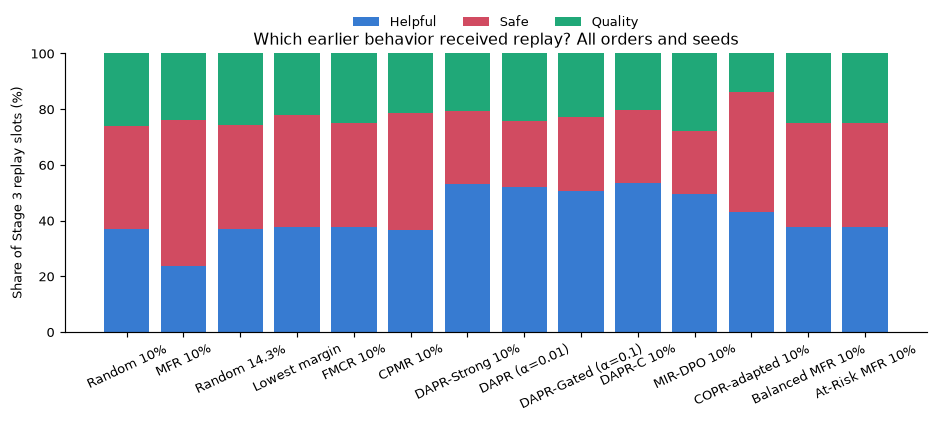

Method,Comparisons,Mean consecutive-interval Jaccard
Random 10%,64,0.04
MFR 10%,64,0.37
Random 14.3%,64,0.07
Lowest margin,64,0.39
FMCR 10%,64,0.38
CPMR 10%,64,0.47
DAPR-Strong 10%,64,0.22
DAPR (α=0.01),64,0.29
DAPR-Gated (α=0.1),64,0.32
DAPR-C 10%,64,0.22


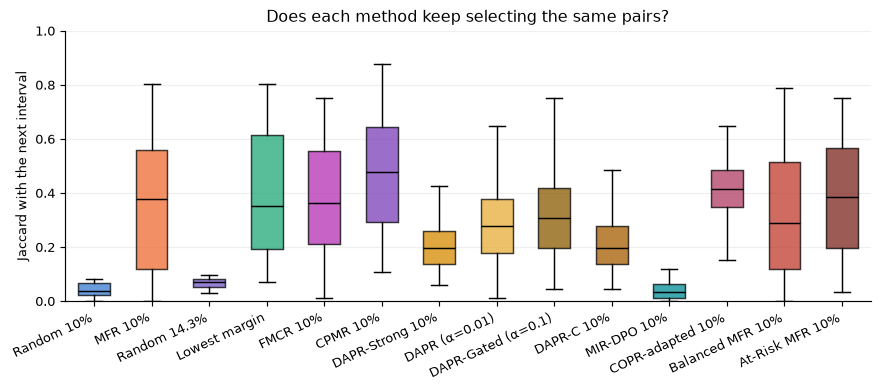

In [14]:
concentration_rows=[]
for keys,g in replay.groupby(['run_name','order_id','seed','stage','method']):
    counts=g.id.value_counts(); probabilities=counts/counts.sum()
    concentration_rows.append({'run_name':keys[0],'order_id':keys[1],'seed':keys[2],
        'stage':keys[3],'method':keys[4],'slots':len(g),'unique_pairs':g.id.nunique(),
        'repeat_rate':1-g.id.nunique()/len(g),'top10_share':counts.head(10).sum()/len(g),
        'effective_pairs':float(np.exp(-(probabilities*np.log(probabilities)).sum()))})
concentration=pd.DataFrame(concentration_rows)
concentration_summary=(concentration.groupby('method').agg(
    **{'Run-stages':('run_name','size'),'Mean slots':('slots','mean'),
       'Mean unique pairs':('unique_pairs','mean'),'Repeat rate (%)':('repeat_rate',lambda x:100*x.mean()),
       'Top-10 slot share (%)':('top10_share',lambda x:100*x.mean()),
       'Effective pairs':('effective_pairs','mean')}).reindex(replay_methods).reset_index()
    .rename(columns={'method':'Method'}))
concentration_summary.Method=concentration_summary.Method.map(MLABEL)
show_table(concentration_summary.round(2),'replay_concentration')
if SAVE_OUTPUTS: concentration.to_csv(OUTPUT_DIR/'replay_concentration_by_run_stage.csv',index=False)

fig,axes=plt.subplots(1,3,figsize=(14,4),constrained_layout=True)
fields=[('unique_pairs','Different pairs per stage'),('repeat_rate','Repeated-slot fraction'),
        ('effective_pairs','Effective number of pairs')]
for ax,(field,title) in zip(axes,fields):
    for x,m in enumerate(replay_methods):
        values=concentration.loc[concentration.method==m,field].to_numpy()
        ax.bar(x,values.mean(),color=MCOLOR[m],alpha=.78)
        jitter=np.linspace(-.13,.13,len(values)) if len(values)>1 else np.array([0.])
        ax.scatter(x+jitter,values,color='black',s=12,alpha=.6,zorder=3)
    ax.set_xticks(range(len(replay_methods)),[MLABEL[m] for m in replay_methods],rotation=35,ha='right')
    ax.set_title(title); ax.grid(axis='y',alpha=.2)
fig.suptitle('Replay diversity across every order, seed, and replay stage')
finish(fig,'16_replay_diversity')

stage3=replay[replay.stage==3]
allocation=(100*stage3.groupby(['method','dataset']).size().unstack(fill_value=0)
            .reindex(index=replay_methods,columns=DATASETS,fill_value=0)
            .div(stage3.groupby('method').size().reindex(replay_methods),axis=0))
allocation_table=allocation.rename(index=MLABEL,columns=DLABEL).reset_index().rename(columns={'method':'Method'})
show_table(allocation_table.round(1),'stage3_dataset_allocation')
fig,ax=plt.subplots(figsize=(9,4.2)); bottom=np.zeros(len(replay_methods))
for d in DATASETS:
    values=allocation[d].fillna(0).to_numpy()
    ax.bar([MLABEL[m] for m in replay_methods],values,bottom=bottom,label=DLABEL[d],color=DCOLOR[d])
    bottom+=values
ax.set_ylim(0,100); ax.set_ylabel('Share of Stage 3 replay slots (%)')
ax.set_title('Which earlier behavior received replay? All orders and seeds')
ax.tick_params(axis='x',rotation=25); ax.legend(frameon=False,ncol=3,loc='upper center',bbox_to_anchor=(.5,1.18))
finish(fig,'17_stage3_dataset_allocation')

stability_rows=[]
for keys,g in replay.groupby(['run_name','order_id','seed','stage','method']):
    sets={i:set(x.id) for i,x in g.groupby('interval')}
    for first,second in zip(sorted(sets)[:-1],sorted(sets)[1:]):
        union=sets[first]|sets[second]
        stability_rows.append({'run_name':keys[0],'order_id':keys[1],'seed':keys[2],
            'stage':keys[3],'method':keys[4],'from_interval':first,'to_interval':second,
            'jaccard':len(sets[first]&sets[second])/len(union) if union else np.nan})
stability=pd.DataFrame(stability_rows)
stability_table=(stability.groupby('method').agg(Comparisons=('jaccard','size'),
    **{'Mean consecutive-interval Jaccard':('jaccard','mean')}).reindex(replay_methods).reset_index()
    .rename(columns={'method':'Method'}))
stability_table.Method=stability_table.Method.map(MLABEL)
show_table(stability_table.round(3),'selection_stability')
fig,ax=plt.subplots(figsize=(8.5,3.8))
for x,m in enumerate(replay_methods):
    values=stability.loc[stability.method==m,'jaccard'].dropna().to_numpy()
    ax.boxplot(values,positions=[x],widths=.55,patch_artist=True,showfliers=False,
               boxprops={'facecolor':MCOLOR[m],'alpha':.75},medianprops={'color':'black'})
ax.set_xticks(range(len(replay_methods)),[MLABEL[m] for m in replay_methods],rotation=25,ha='right')
ax.set_ylim(0,1); ax.set_ylabel('Jaccard with the next interval')
ax.set_title('Does each method keep selecting the same pairs?'); ax.grid(axis='y',alpha=.2)
finish(fig,'18_selection_stability')


## 13. Had the replayed pairs actually regressed?

For every replayed slot: was the pair's current margin below its own peak margin (genuinely forgotten), and was it ever learned (peak margin > 0)? Lowest-margin selection can spend slots on pairs that were never learned rather than forgotten.

In [15]:
import sys
sys.path.insert(0, str(REPO/'src'))
import mfr_analysis

analysis_runs = mfr_analysis.load_runs(ARTIFACT_DIR, quiet=True, completed_only=True,
                                       protocol_version=protocol['protocol_version'])
share = mfr_analysis.replay_regression_share(analysis_runs)
if share.empty:
    print('No replay logs with selection scores found.')
else:
    t = (share.groupby('method', observed=True)[['regressed_pct','never_learned_pct','regressed_and_learned_pct']]
         .mean().reindex([m for m in METHODS if m in set(share.method)]).reset_index())
    t.columns = ['Method','Regressed below peak (%)','Never learned (%)','Learned and regressed (%)']
    t.Method = t.Method.map(MLABEL)
    show_table(t, 'replay_regression_share')


Method,Regressed below peak (%),Never learned (%),Learned and regressed (%)
MFR 10%,86.94,12.78,75.62
Lowest margin,53.58,50.31,42.12
DAPR-Strong 10%,29.98,44.82,27.59
DAPR (α=0.01),31.14,47.89,28.35
DAPR-Gated (α=0.1),28.27,55.18,24.92
DAPR-C 10%,29.53,44.82,27.03
COPR-adapted 10%,60.75,68.05,30.07
Balanced MFR 10%,93.27,13.80,86.20


## 14. CPMR projection check

This final mechanism check is intentionally CPMR-only because the other methods do not calculate a counterfactual projected margin. It asks whether CPMR selected pairs that its simulation expected to deteriorate, and whether their later observed margin was above the no-replay projection. All three datasets are shown.

`Observed − projected` is an intervention diagnostic, not a normal prediction error: the projected value assumes no replay, while the observed value comes after real training that included replay. A positive value is consistent with replay helping the selected pair, but it is not a causal estimate by itself.


Dataset,Group,Rows,Mean current margin,Mean projected margin,Mean predicted drop
Helpful,Available buffer,11404,0.02,0.03,-0.00
Helpful,Selected by CPMR,1096,-0.01,-0.01,0.00
Quality,Available buffer,13732,0.04,0.04,0.00
Quality,Selected by CPMR,1268,-0.02,-0.02,0.01
Safe,Available buffer,11312,0.07,0.06,0.01
Safe,Selected by CPMR,1188,-0.03,-0.04,0.01


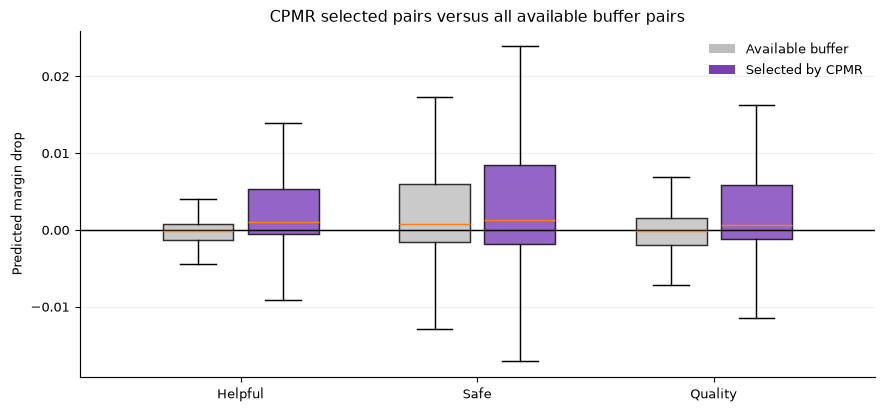

Dataset,Replayed pairs,Mean observed minus projected,Positive difference (%)
Helpful,911,0.01,91.33
Safe,969,0.01,79.36
Quality,1064,0.02,90.79


In [16]:
if 'cpmr' not in replay_methods:
    print('CPMR is not complete yet. Rerun this notebook after its run folders contain COMPLETE.json.')
else:
    snapshots=[]
    for r in records.values():
        if r['method']!='cpmr': continue
        for stage in range(2,len(r['order'])+1):
            folder=stage_folder(r,stage)
            for path in sorted(folder.glob('cpmr_refresh_*.csv')):
                interval=int(path.stem.rsplit('_',1)[1])
                frame=pd.read_csv(path)
                selected=set(replay[(replay.run_name==r['run_name'])&(replay.stage==stage)&
                    (replay.interval==interval)].id)
                frame['selected']=frame.id.isin(selected)
                frame['run_name']=r['run_name']; frame['order_id']=r['order_id']; frame['seed']=r['seed']
                frame['stage']=stage; frame['interval']=interval
                snapshots.append(frame)
    candidates=pd.concat(snapshots,ignore_index=True) if snapshots else pd.DataFrame()
    if candidates.empty:
        print('CPMR runs exist, but no cpmr_refresh_*.csv snapshots were found.')
    else:
        projection=(candidates.groupby(['dataset','selected']).agg(
            Rows=('id','size'),**{'Mean current margin':('current_margin','mean'),
            'Mean projected margin':('projected_margin','mean'),
            'Mean predicted drop':('predicted_drop','mean')}).reset_index())
        projection['Dataset']=projection.dataset.map(DLABEL)
        projection['Group']=projection.selected.map({False:'Available buffer',True:'Selected by CPMR'})
        show_table(projection[['Dataset','Group','Rows','Mean current margin','Mean projected margin',
                               'Mean predicted drop']].round(4),'cpmr_projection_summary')
        fig,ax=plt.subplots(figsize=(8.5,4))
        positions=[]; values=[]; colors=[]; labels=[]
        for x,d in enumerate(DATASETS):
            for offset,selected,color,label in [(-.18,False,'#bdbdbd','Available buffer'),
                                                 (.18,True,MCOLOR['cpmr'],'Selected by CPMR')]:
                v=candidates[(candidates.dataset==d)&(candidates.selected==selected)].predicted_drop.dropna()
                if len(v): positions.append(x+offset); values.append(v); colors.append(color); labels.append(label)
        boxes=ax.boxplot(values,positions=positions,widths=.3,patch_artist=True,showfliers=False)
        for box,color in zip(boxes['boxes'],colors): box.set_facecolor(color); box.set_alpha(.8)
        ax.axhline(0,color='black',lw=1); ax.set_xticks(range(len(DATASETS)),[DLABEL[d] for d in DATASETS])
        ax.set_ylabel('Predicted margin drop'); ax.set_title('CPMR selected pairs versus all available buffer pairs')
        from matplotlib.patches import Patch
        ax.legend(handles=[Patch(facecolor='#bdbdbd',label='Available buffer'),
                           Patch(facecolor=MCOLOR['cpmr'],label='Selected by CPMR')],frameon=False)
        ax.grid(axis='y',alpha=.2); finish(fig,'19_cpmr_projection_selection')
        if SAVE_OUTPUTS: candidates.to_csv(OUTPUT_DIR/'cpmr_candidate_snapshots.csv',index=False)
    observed=replay[(replay.method=='cpmr')&replay.get('observed_minus_projected',pd.Series(index=replay.index,dtype=float)).notna()]
    if len(observed):
        intervention=(observed.groupby('dataset').agg(
            **{'Replayed pairs':('id','size'),
               'Mean observed minus projected':('observed_minus_projected','mean'),
               'Positive difference (%)':('observed_minus_projected',lambda x:100*(x>0).mean())})
            .reindex(DATASETS).reset_index())
        intervention['Dataset']=intervention.dataset.map(DLABEL)
        show_table(intervention[['Dataset','Replayed pairs','Mean observed minus projected',
                                 'Positive difference (%)']].round(3),'cpmr_intervention_diagnostic')


## 15. DAPR-Gated activation check

DAPR-Gated checks each replay pair immediately before its optimizer step. The next tables show how often the directional anchor was actually active. A rate near 100% means the method behaved almost like DAPR-Strong; a lower rate means the gate frequently released pairs that had not regressed below their stored peak margin.

**Note about `NaN`:** For anchor-rate columns, `NaN` means that the gate was off for every replay pair in that training step, so there was no active anchor to measure. It is expected and does not mean that the run failed or that data is missing.


In [17]:
gated=replay[replay.method=='dapr_gated'].copy()
required={'anchor_gate_active','gate_current_margin','gate_peak_margin','gate_margin_drop'}
if gated.empty:
    print('DAPR-Gated is not complete yet. Rerun this notebook after its run folders contain COMPLETE.json.')
elif not required<=set(gated.columns):
    print('DAPR-Gated replay logs are missing gate diagnostics:', sorted(required-set(gated.columns)))
else:
    gated['Gate active']=(gated.anchor_gate_active.astype(str).str.lower()=='true')
    def gate_table(group_columns):
        return (gated.groupby(group_columns,dropna=False).agg(
            **{'Replay occurrences':('id','size'),
               'Gate active (%)':('Gate active',lambda x:100*x.mean()),
               'Mean peak minus current':('gate_margin_drop','mean')})
            .reset_index())
    by_cell=gate_table(['order_id','seed']).rename(columns={'order_id':'Order','seed':'Seed'})
    by_stage=gate_table(['stage','trained_on']).rename(columns={'stage':'Stage','trained_on':'Learning now'})
    by_source=gate_table(['dataset']).rename(columns={'dataset':'Replay source'})
    by_interval=gate_table(['interval']).rename(columns={'interval':'Interval'})
    by_stage['Learning now']=by_stage['Learning now'].map(DLABEL)
    by_source['Replay source']=by_source['Replay source'].map(DLABEL)
    show_table(by_cell,'dapr_gated_gate_rate_by_cell')
    show_table(by_stage,'dapr_gated_gate_rate_by_stage')
    show_table(by_source,'dapr_gated_gate_rate_by_source')
    show_table(by_interval,'dapr_gated_gate_rate_by_interval')


Order,Seed,Replay occurrences,Gate active (%),Mean peak minus current
1,0,444,31.98,-0.01
1,1,444,32.88,-0.01
2,0,444,27.48,-0.02
2,1,444,26.58,-0.01
3,0,444,30.86,-0.01
3,1,444,30.18,-0.02
4,0,444,28.83,-0.01
4,1,444,31.98,-0.01


Stage,Learning now,Replay occurrences,Gate active (%),Mean peak minus current
2,Helpful,888,25.90,-0.02
2,Safe,888,37.73,-0.01
3,Helpful,444,24.77,-0.01
3,Quality,888,28.72,-0.01
3,Safe,444,31.31,-0.01


Replay source,Replay occurrences,Gate active (%),Mean peak minus current
Helpful,1345,36.43,-0.00
Quality,1294,29.91,-0.01
Safe,913,21.03,-0.02


Interval,Replay occurrences,Gate active (%),Mean peak minus current
1,736,25.82,-0.01
2,736,47.28,-0.01
3,736,32.88,-0.01
4,736,26.49,-0.01
5,608,15.46,-0.02


## Balanced and At-Risk MFR: where the replay slots went

Share of replay slots per old behavior, unique pairs replayed, and (At-Risk only) the share of slots taken from the failure tier (`current_policy_margin <= 0`).

In [18]:
quota_rows=[]
for run in sorted((ARTIFACT_DIR/'runs').glob('v2_o*_s*')):
    settings_path=run/'settings.json'
    if not settings_path.exists(): continue
    settings=json.loads(settings_path.read_text())
    if settings.get('method') not in ('mfr','mfr_balanced','mfr_at_risk'): continue
    for log_path in sorted(run.glob('stage*/replay_log.csv')):
        log=pd.read_csv(log_path)
        if log.empty: continue
        row={'Method':MLABEL[settings['method']],'Run':run.name,'Stage':log_path.parent.name,
             'Replay slots':len(log),'Unique pairs':log['id'].nunique(),
             'Largest behavior share (%)':100*log['dataset'].value_counts(normalize=True).max()}
        if 'risk_tier' in log:
            row['Failure-tier slots (%)']=100*(log['risk_tier']==0).mean()
        quota_rows.append(row)
quota_table=pd.DataFrame(quota_rows)
if quota_table.empty:
    print('No MFR, Balanced MFR or At-Risk MFR replay logs found yet.')
else:
    show_table(quota_table.groupby('Method').mean(numeric_only=True).round(1).reset_index(),'balanced_at_risk_allocation')


Method,Replay slots,Unique pairs,Largest behavior share (%),Failure-tier slots (%)
At-Risk MFR 10%,222.0,117.3,75.0,100.0
Balanced MFR 10%,222.0,132.2,75.0,—
MFR 10%,222.0,126.9,83.9,—
